In [1]:
import torch
import torch.nn as nn
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, ControlNetModel
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from torchvision import transforms
import nibabel as nib
from tqdm.auto import tqdm
import lpips # LPIPS用
from skimage.metrics import peak_signal_noise_ratio as psnr # PSNR用
from skimage.metrics import structural_similarity as ssim # SSIM用

# --- ローカルGPUの設定 ---
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
# ===================================================================
# 学習時と全く同じモデルクラス（CustomConditionalLDM）を再定義
# ===================================================================
class CustomConditionalLDM(nn.Module):
    def __init__(self, pretrained_model_name="runwayml/stable-diffusion-v1-5"):
        super().__init__()
        self.vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae")
        self.tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
        self.text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder")
        self.unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet")
        self.scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
        self.controlnet = ControlNetModel.from_config(self.unet.config)
        
        in_channels = 4
        out_channels = self.controlnet.conv_in.out_channels
        self.controlnet.controlnet_cond_embedding = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        )
        for module in self.controlnet.controlnet_cond_embedding.modules():
            if isinstance(module, nn.Conv2d):
                torch.nn.init.zeros_(module.weight)
                torch.nn.init.zeros_(module.bias)

        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.unet.requires_grad_(False)

In [3]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from torchvision import transforms
import nibabel as nib
import os

# ===================================================================
# データセットクラスも再定義が必要
# ★★★ 学習時と全く同じ【完成版】のクラス定義を使用 ★★★
# ===================================================================
class BrainMetsDataset(Dataset):
    """
    【完成版】
    学習時・評価時と互換性のあるクラス。
    ベースライン、未来画像、マスク、ファイル名など、全ての情報を返す。
    """
    def __init__(self, csv_file, image_root_dir, patient_ids, mode, image_size=256, latent_size=32):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        
        self.image_root_dir = image_root_dir
        self.seg_dir = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
        self.mode = mode
        self.image_size = image_size
        self.latent_size = latent_size
        self.pairs = self._create_pairs()
        
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.image_size, self.image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])
        
        self.mask_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.latent_size, self.latent_size), antialias=False)
        ])

    def _create_pairs(self):
        # 学習時と同じペア作成ロジック
        pairs = []
        for _, group in self.data.groupby('PatientID'):
            baseline_scans = group[group['FinalPattern'] == 'Baseline']
            future_scans = group[group['FinalPattern'] != 'Baseline']
            if baseline_scans.empty or future_scans.empty: continue
            for _, baseline_row in baseline_scans.iterrows():
                for _, future_row in future_scans.iterrows():
                    pairs.append({
                        "baseline_file": baseline_row['FileName'],
                        "future_file": future_row['FileName'],
                        "condition": future_row['FinalPattern']
                    })
        print(f"Found {len(pairs)} pairs for '{self.mode}' set.")
        return pairs

    def __len__(self):
        return len(self.pairs)

    def _get_full_path(self, directory, filename, is_mask=False):
        name_without_ext = filename.replace('.nii.gz', '')
        suffix = "_0000.nii.gz" if not is_mask else ".nii.gz"
        final_filename = f"{name_without_ext}{suffix}"
        return os.path.join(directory, final_filename)

    def _load_and_process_image(self, path):
        nii = nib.load(path)
        data = nii.get_fdata().astype('float32')
        slice_img = data[:, :, data.shape[2] // 2]
        if slice_img.max() > slice_img.min():
            slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
        return slice_img

    def _load_and_process_mask(self, path):
        nii = nib.load(path)
        data = nii.get_fdata().astype('float32')
        slice_img = data[:, :, data.shape[2] // 2]
        return self.mask_transform(slice_img)

    def __getitem__(self, idx):
        pair = self.pairs[idx]
        try:
            baseline_path = self._get_full_path(self.image_root_dir, pair['baseline_file'])
            future_path = self._get_full_path(self.image_root_dir, pair['future_file'])
            mask_path = self._get_full_path(self.seg_dir, pair['future_file'], is_mask=True)

            baseline_image = self.transform(self._load_and_process_image(baseline_path)).repeat(3, 1, 1)
            future_image = self.transform(self._load_and_process_image(future_path)).repeat(3, 1, 1)
            future_mask = self._load_and_process_mask(mask_path)
            
            patient_id_str = self.data[self.data['FileName'] == pair['baseline_file']]['PatientID'].values[0]

            return {
                "baseline_image": baseline_image,
                "future_image": future_image, # 💡 これで正しく返される
                "baseline_filename": pair['baseline_file'],
                "condition_label": pair['condition'],
                "patient_id": patient_id_str,
                "future_mask": future_mask
            }
        except FileNotFoundError as e:
            print(f"Warning: File not found ({e}). Skipping this pair.")
            return self.__getitem__((idx + 1) % len(self))

# ===================================================================
# テストデータの準備 (この部分は変更なし)
# ===================================================================
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)
# 定量評価用のローダーもここで作成
test_dataloader_eval = DataLoader(test_dataset, batch_size=1, shuffle=False)

print("\n✅ Test dataloaders are ready.")

Found 1091 pairs for 'test' set.

✅ Test dataloaders are ready.


In [4]:
# ===================================================================
# 1. モデルのインスタンス化と重みの読み込み
# ===================================================================
print("Initializing the model structure...")
model = CustomConditionalLDM().to(device)

CONTROLNET_WEIGHTS_PATH = '/home/masaki/mystudy/trained_models_l+c_150/best_model_epoch_124.pth'
model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=device))
model.eval() # モデルを推論モードに設定

print(f"✅ Best model weights loaded from: {CONTROLNET_WEIGHTS_PATH}")

# ===================================================================
# 2. テストデータの準備
# ===================================================================
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

# --- テストデータローダーを作成 ---
test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

print("\n✅ Test dataloader is ready.")

Initializing the model structure...


/tmp/ipykernel_1933350/104112503.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=device

✅ Best model weights loaded from: /home/masaki/mystudy/trained_models_l+c_150/best_model_epoch_124.pth
Found 1091 pairs for 'test' set.

✅ Test dataloader is ready.



--- Starting Qualitative Evaluation (Visual Inspection) ---

--- Processing sample 1/3 for patient: YG_J7TDRWNCQ0HR ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


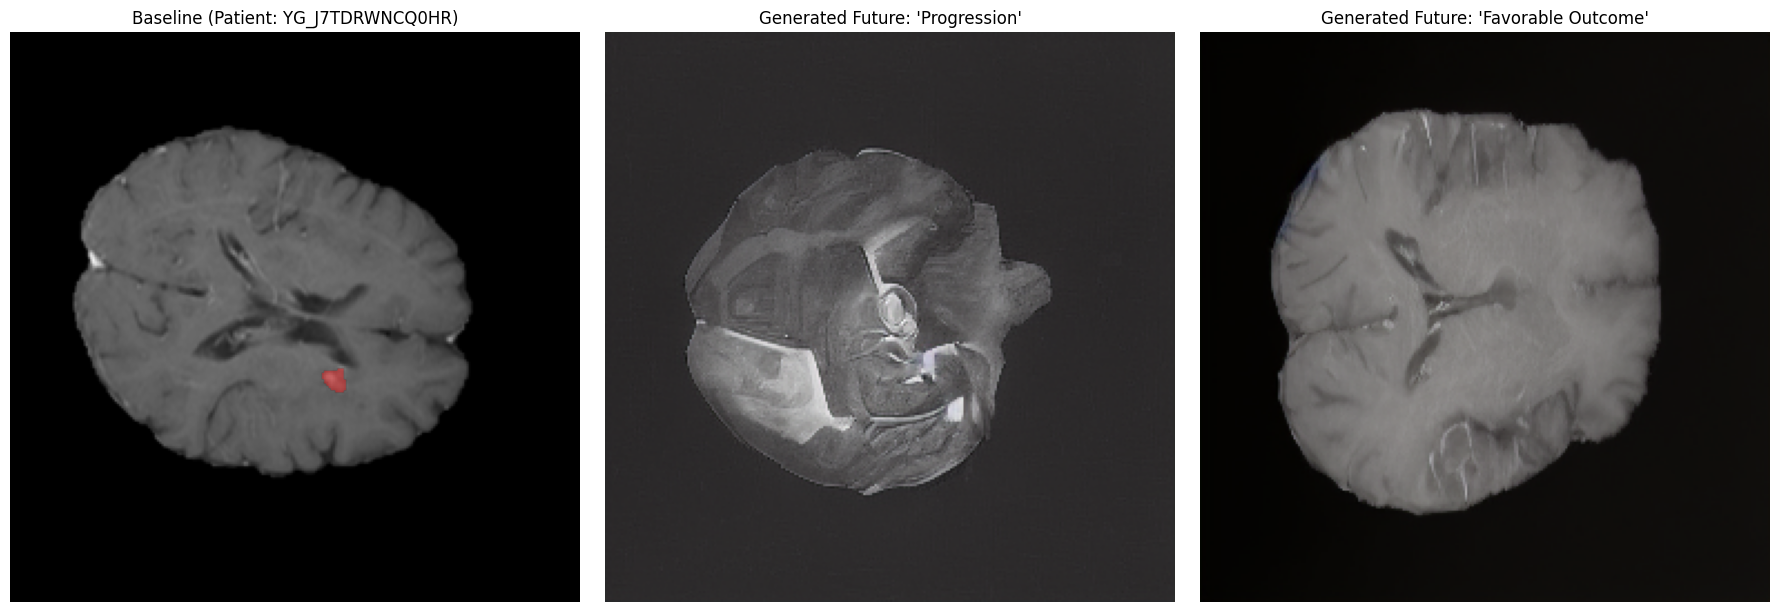


--- Processing sample 2/3 for patient: YG_6ZVU9E0I763T ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


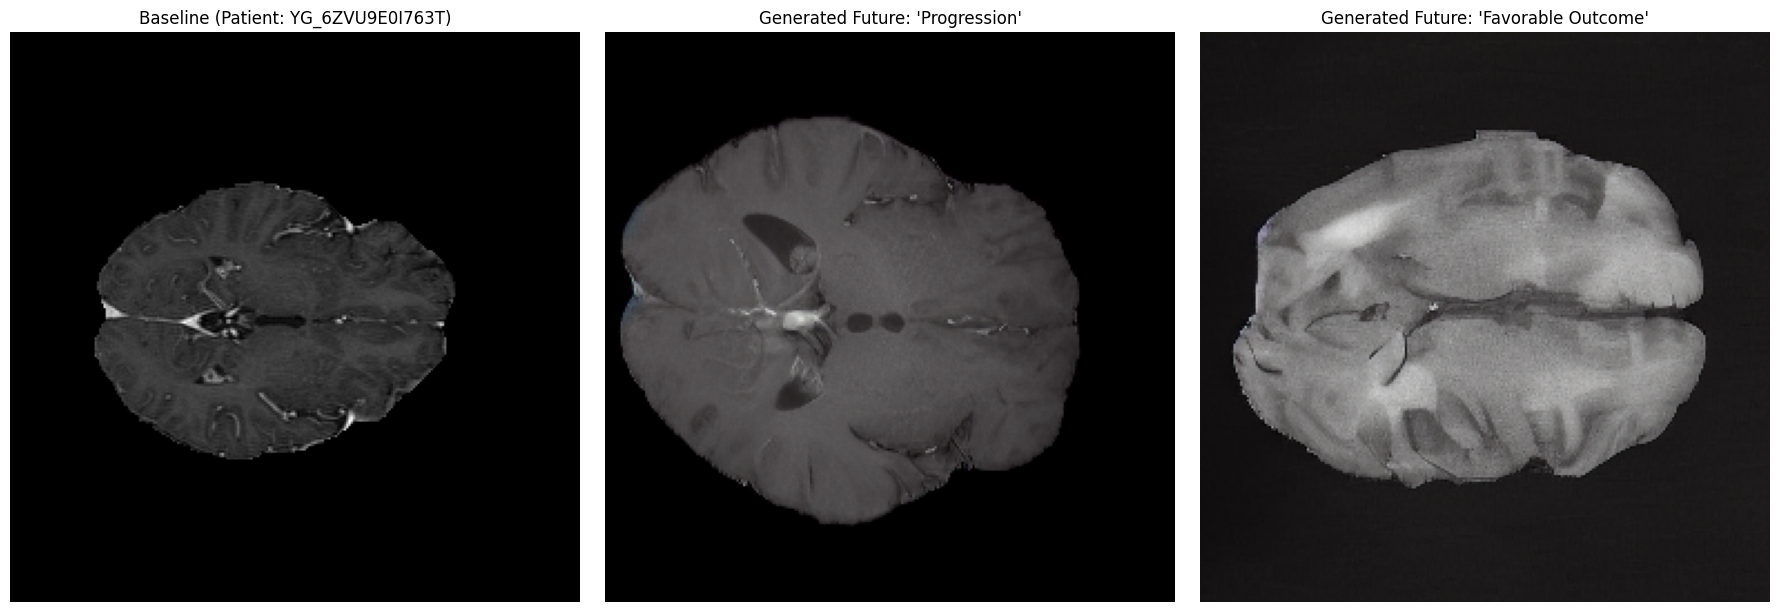


--- Processing sample 3/3 for patient: YG_4LH8PG2REEFI ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


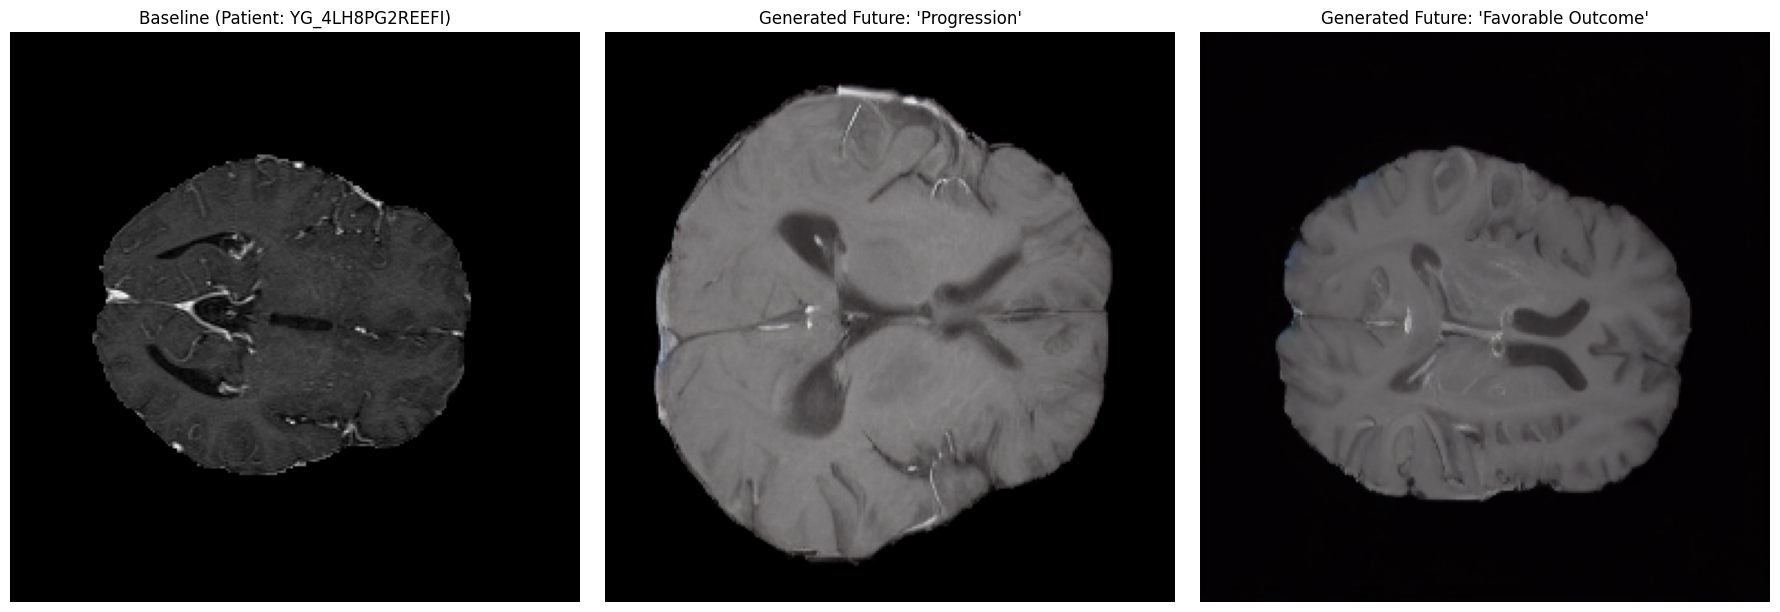


🎉 Qualitative evaluation finished for 3 samples! 🎉


In [5]:
# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50, return_tensor=False):
    # (return_tensor引数を追加)
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    for t in tqdm(model.scheduler.timesteps, desc=f"Denoising ({condition_label})"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image_tensor = model.vae.decode(latents).sample
    
    if return_tensor:
        return image_tensor # [-1, 1] の範囲のTensorを返す

    # PIL.Image形式に変換
    image = (image_tensor / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# ===================================================================
# ヘルパー関数
# ===================================================================
def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# ===================================================================
# 【定性的評価】複数の患者の結果を可視化
# ===================================================================
print("\n--- Starting Qualitative Evaluation (Visual Inspection) ---")
NUM_SAMPLES_TO_SHOW = 3 # 表示したい患者の人数
SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'

for i, sample_batch in enumerate(test_dataloader):
    if i >= NUM_SAMPLES_TO_SHOW:
        break

    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    baseline_filename = sample_batch["baseline_filename"][0]
    print(f"\n--- Processing sample {i+1}/{NUM_SAMPLES_TO_SHOW} for patient: {patient_id} ---")

    progression_image = generate_future_image(model, baseline_image, "Progression")
    favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")
    
    seg_path = os.path.join(SEG_DIR, baseline_filename)
    seg_mask_rgba = None
    try:
        seg_nii = nib.load(seg_path)
        seg_data = seg_nii.get_fdata().astype('float32')
        seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
        seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
        seg_mask = np.array(seg_slice_pil)
        seg_mask_rgba = np.zeros((256, 256, 4))
        seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%
        print("✅ Segmentation mask loaded for visualization.")
    except FileNotFoundError:
        print(f"⚠️ Warning: Segmentation mask not found at {seg_path}")

    plt.figure(figsize=(18, 6))
    plt.subplot(1, 3, 1)
    plt.imshow(to_pil(baseline_image), cmap='gray')
    if seg_mask_rgba is not None: plt.imshow(seg_mask_rgba)
    plt.title(f"Baseline (Patient: {patient_id})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(progression_image, cmap='gray')
    plt.title("Generated Future: 'Progression'")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(favorable_image, cmap='gray')
    plt.title("Generated Future: 'Favorable Outcome'")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

print(f"\n🎉 Qualitative evaluation finished for {NUM_SAMPLES_TO_SHOW} samples! 🎉")

In [6]:
# ===================================================================
# 【定量的評価】FIDのみの計算 (時間短縮版)
# ===================================================================
import torch
import numpy as np
from tqdm.auto import tqdm
from torchmetrics.image.fid import FrechetInceptionDistance

print("\n--- Starting Quantitative Evaluation (FID Only) ---")

# --- FIDモデルの初期化（ProgressionとFavorableで分ける） ---
# feature=2048 は標準的なInceptionV3の最終プーリング層の特徴量
fid_prog = FrechetInceptionDistance(feature=2048).to(device)
fid_fav = FrechetInceptionDistance(feature=2048).to(device)

# FID用にテンソルを変換する関数（[-1, 1] -> [0, 255] uint8 RGB）
def preprocess_for_fid(img_tensor):
    img = (img_tensor / 2 + 0.5).clamp(0, 1) * 255.0
    img = img.to(torch.uint8)
    if img.shape[1] == 1: # グレースケール(1ch)なら3チャンネルにコピー
        img = img.repeat(1, 3, 1, 1)
    return img

for batch in tqdm(test_dataloader_eval, desc="Calculating FID"):
    
    # --- 1. データを準備 ---
    baseline_image = batch["baseline_image"].to(device)
    real_future_image = batch["future_image"].to(device)
    condition_label = batch["condition_label"][0]
    
    # --- 2. 画像を生成 (ここが一番時間がかかります) ---
    generated_future_image = generate_future_image(model, baseline_image, condition_label, return_tensor=True)
    
    # --- 3. FID用に画像を変換 ---
    real_fid_img = preprocess_for_fid(real_future_image)
    gen_fid_img = preprocess_for_fid(generated_future_image)

    # --- 4. スコアを分類して蓄積 ---
    if condition_label == "Progression":
        # 実画像と生成画像をそれぞれモデルに蓄積
        fid_prog.update(real_fid_img, real=True)
        fid_prog.update(gen_fid_img, real=False)
    else:
        fid_fav.update(real_fid_img, real=True)
        fid_fav.update(gen_fid_img, real=False)

# ===================================================================
# 最終結果の計算と表示
# ===================================================================
print("\nCalculating final FID scores... (This may take a moment)")

# 蓄積したデータからFIDを計算
prog_fid_score = fid_prog.compute().item()
fav_fid_score = fid_fav.compute().item()

print("\n--- Quantitative Evaluation Results ---")
print("\n--- 'Progression' Category ---")
print(f"FID (↓ is better): {prog_fid_score:.4f}")

print("\n--- 'Favorable Outcome' Category ---")
print(f"FID (↓ is better): {fav_fid_score:.4f}")

print("\n🎉 FID evaluation finished! 🎉")


--- Starting Quantitative Evaluation (FID Only) ---


Calculating FID:   0%|          | 0/1091 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]

... (2,175 outputs left out)

Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Calculating final FID scores... (This may take a moment)

--- Quantitative Evaluation Results ---

--- 'Progression' Category ---
FID (↓ is better): 66.4111

--- 'Favorable Outcome' Category ---
FID (↓ is better): 137.2989

🎉 FID evaluation finished! 🎉


In [6]:
# ===================================================================
# 【定量的評価】LPIPS, PSNR, SSIM の計算
# ===================================================================
print("\n--- Starting Quantitative Evaluation (Numerical Scores) ---")

# LPIPSの評価モデルをロード
loss_fn_lpips = lpips.LPIPS(net='alex').to(device)

# スコアを保存するリスト
prog_lpips_scores = []
prog_psnr_scores = []
prog_ssim_scores = []
fav_lpips_scores = []
fav_psnr_scores = []
fav_ssim_scores = []

# (test_dataloader_eval はセル3で定義済みと仮定)
for batch in tqdm(test_dataloader_eval, desc="Quantitative Evaluation"):
    
    # --- 1. データを準備 ---
    baseline_image = batch["baseline_image"].to(device)
    real_future_image = batch["future_image"].to(device)
    condition_label = batch["condition_label"][0]
    
    # ★★★ 修正点：正しいキー名でファイル名を取得 ★★★
    baseline_filename = batch["baseline_filename"][0] 
    
    # --- 2. 画像を生成 ---
    generated_future_image = generate_future_image(model, baseline_image, condition_label, return_tensor=True)
    
    # --- 3. LPIPSの計算 ---
    lpips_score = loss_fn_lpips(real_future_image, generated_future_image).item()
    
    # --- 4. PSNR/SSIMの計算準備 ---
    real_np = (real_future_image[0, 0, :, :].cpu().numpy() / 2 + 0.5).clip(0, 1)
    gen_np = (generated_future_image[0, 0, :, :].cpu().numpy() / 2 + 0.5).clip(0, 1)
    
    # --- 5. PSNR/SSIMの計算 ---
    psnr_score = psnr(real_np, gen_np, data_range=1.0)
    ssim_score = ssim(real_np, gen_np, data_range=1.0)
    
    # --- 6. スコアを分類して保存 ---
    if condition_label == "Progression":
        prog_lpips_scores.append(lpips_score)
        prog_psnr_scores.append(psnr_score)
        prog_ssim_scores.append(ssim_score)
    else:
        fav_lpips_scores.append(lpips_score)
        fav_psnr_scores.append(psnr_score)
        fav_ssim_scores.append(ssim_score)

# ===================================================================
# 最終結果の集計と表示
# ===================================================================
def get_stats(scores):
    scores_np = np.array(scores)
    return np.mean(scores_np), np.std(scores_np)

prog_lpips_mean, prog_lpips_std = get_stats(prog_lpips_scores)
prog_psnr_mean, prog_psnr_std = get_stats(prog_psnr_scores)
prog_ssim_mean, prog_ssim_std = get_stats(prog_ssim_scores)

fav_lpips_mean, fav_lpips_std = get_stats(fav_lpips_scores)
fav_psnr_mean, fav_psnr_std = get_stats(fav_psnr_scores)
fav_ssim_mean, fav_ssim_std = get_stats(fav_ssim_scores)

print("\n--- Quantitative Evaluation Results ---")
print("\n--- 'Progression' Category ---")
print(f"LPIPS (↓ is better): {prog_lpips_mean:.4f} ± {prog_lpips_std:.4f}")
print(f"PSNR (↑ is better):  {prog_psnr_mean:.4f} ± {prog_psnr_std:.4f}")
print(f"SSIM (↑ is better):  {prog_ssim_mean:.4f} ± {prog_ssim_std:.4f}")

print("\n--- 'Favorable Outcome' Category ---")
print(f"LPIPS (↓ is better): {fav_lpips_mean:.4f} ± {fav_lpips_std:.4f}")
print(f"PSNR (↑ is better):  {fav_psnr_mean:.4f} ± {fav_psnr_std:.4f}")
print(f"SSIM (↑ is better):  {fav_ssim_mean:.4f} ± {fav_ssim_std:.4f}")

print("\n🎉 Quantitative evaluation finished! 🎉")


--- Starting Quantitative Evaluation (Numerical Scores) ---
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/lpips/weights/v0.1/alex.pth


Quantitative Evaluation:   0%|          | 0/1091 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]

... (2,177 outputs left out)

Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


--- Quantitative Evaluation Results ---

--- 'Progression' Category ---
LPIPS (↓ is better): 0.3627 ± 0.1140
PSNR (↑ is better):  15.5659 ± 3.1010
SSIM (↑ is better):  0.3362 ± 0.2162

--- 'Favorable Outcome' Category ---
LPIPS (↓ is better): 0.3481 ± 0.1229
PSNR (↑ is better):  16.0023 ± 2.7512
SSIM (↑ is better):  0.3182 ± 0.2215

🎉 Quantitative evaluation finished! 🎉
